# 01 · Data, target and exploratory analysis

**Goal of this notebook**

1. Load Lending Club loans and fix the sample: 36-month loans issued 2010–2017.
2. Define the target: **default (90+ days past due) within 12 months of issue**,
   and check how well it can be reconstructed from the public data.
3. Decide, column by column, what may enter the model (leakage control).
4. Explore the data: default rates, missingness, anomalies.

Every decision taken here is listed in the **Conclusions** section at the end,
because the validator in Part 2 will review them.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

from src.data import (INTERIM_PATH, TARGET, TARGET_LIFETIME, HORIZON_MONTHS, DPD_MONTHS,
                      BUFFER_MONTHS, BAD_STATUSES, GOOD_STATUSES, build_interim, load_interim,
                      make_modelling_base, vintage_table, snapshot_date, months_paid, default_month)
from src.features_config import (GROUPS, TARGET_ONLY_COLS, column_table, check_coverage,
                                  assert_no_leakage)

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50, "display.width", 140)

def save(fig, name):
    fig.savefig(FIG / f"01_{name}.png", dpi=120, bbox_inches="tight")

## 1. Load data

The raw CSV is 1.6 GB. It is read once, filtered to 36-month loans and saved as
parquet in `data/interim/`; later runs load the parquet in seconds.

In [2]:
if not INTERIM_PATH.exists():
    build_interim()
loans = load_interim()
snapshot = snapshot_date(loans)
print(f"36-month loans, all years: {len(loans):,} rows x {loans.shape[1]} columns")
print(f"Data snapshot (latest payment month in the file): {snapshot:%Y-%m}")

36-month loans, all years: 1,609,754 rows x 152 columns
Data snapshot (latest payment month in the file): 2019-03


## 2. Why a 12-month target

The data was extracted in March 2019, so recent vintages still contain many open
loans. A **lifetime** target ("did the loan end in default?") is only known for
closed loans. Dropping open loans from recent years keeps mainly loans that closed
**early**, and early closure is linked to the outcome, so the lifetime default
rate of those years is biased. With a lifetime target the sample would have to
stop at 2015.

A **12-month** target asks a question every loan older than 12 months can answer:
*did it reach 90+ days past due in its first 12 months?* This is also the bank
standard: the regulatory PD is a one-year probability, and 90 days past due is
the default definition of CRR Art. 178.

In [3]:
vt = vintage_table(loans)
vt

,loans,open_share,dr_lifetime,dr_12m
issue_year,,,,
2007,603,0.000,0.262,0.058
2008,2393,0.000,0.207,0.069
2009,5281,0.000,0.137,0.052
2010,9156,0.000,0.109,0.035
2011,14101,0.000,0.106,0.031
2012,43470,0.000,0.136,0.037
2013,100422,0.000,0.123,0.029
2014,162570,0.000,0.137,0.029
2015,283173,0.000,0.149,0.036


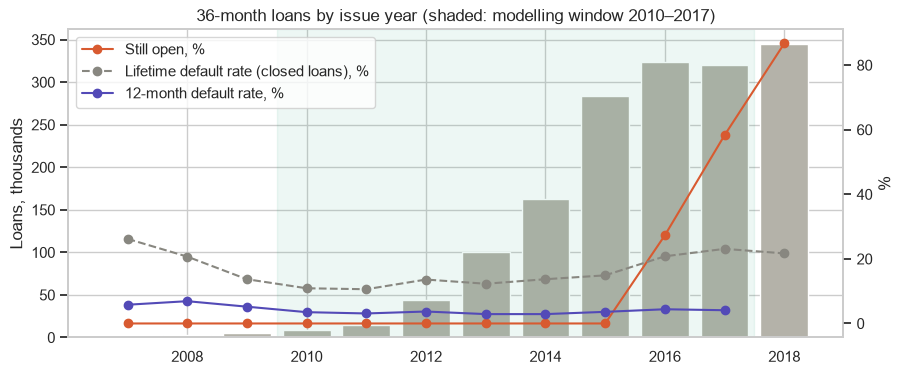

In [4]:
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(vt.index, vt["loans"] / 1000, color="#B4B2A9")
ax1.set_ylabel("Loans, thousands")
ax2 = ax1.twinx()
ax2.plot(vt.index, vt["open_share"] * 100, "o-", color="#D85A30", label="Still open, %")
ax2.plot(vt.index, vt["dr_lifetime"] * 100, "o--", color="#888780", label="Lifetime default rate (closed loans), %")
ax2.plot(vt.index, vt["dr_12m"] * 100, "o-", color="#534AB7", label="12-month default rate, %")
ax2.set_ylabel("%")
ax2.grid(False)
ax1.axvspan(2009.5, 2017.5, color="#1D9E75", alpha=0.08)
ax2.legend(loc="upper left")
ax1.set_title("36-month loans by issue year (shaded: modelling window 2010–2017)")
save(fig, "vintages")
plt.show()

**Reading the chart.** The lifetime default rate jumps in 2016–2017 together with
the share of open loans: that jump is the early-closure bias. The 12-month default
rate does not depend on open loans and stays in a narrow band. 2007–2009 are small
and were issued during the financial crisis. The modelling window is
**2010–2017**, with 2017 reserved as the out-of-time year. 2018 loans have not yet
been observed for 12 months.

## 3. Target definition

The public data has **no monthly payment history**: only the current status and
cumulative amounts. The month of default is therefore reconstructed:

```
months_paid   = floor((total_rec_prncp + total_rec_int) / installment)
default_month = months_paid + 1 + 3     # first missed instalment, then 90 days
target        = 1  if status is bad and default_month <= 12
                0  otherwise
```

| Part | Choice |
|---|---|
| Bad statuses | Charged Off, Default, Late (31–120 days), Does not meet the credit policy. Status:Charged Off |
| Good | everything else, including loans still open and loans that defaulted after month 12 |
| Eligible | `issue_d + 12 months + 3 months buffer <= snapshot` |
| Lifetime target | kept as `target_lifetime` for comparison, NaN for open loans |

Principal and interest are used, not `total_pymnt`: total payments also contain
late fees and post charge-off recoveries, which would push the default month later.
These columns are listed in `TARGET_ONLY_COLS` and are never model features.

In [5]:
base = make_modelling_base(loans)
print(f"Modelling base: {len(base):,} loans, issued {base['issue_d'].min():%Y-%m} to {base['issue_d'].max():%Y-%m}")
print(f"12-month default rate: {base[TARGET].mean():.2%}")
pd.crosstab(base["loan_status"], base[TARGET], margins=True)

Modelling base: 1,256,806 loans, issued 2010-01 to 2017-12
12-month default rate: 3.77%


target,0,1,All
loan_status,,,
Charged Off,109626,47276,156902
Current,270645,0,270645
Default,21,0,21
Does not meet the credit policy. Status:Charged Off,87,71,158
Does not meet the credit policy. Status:Fully Paid,532,0,532
Fully Paid,816044,0,816044
In Grace Period,2965,0,2965
Late (16-30 days),1546,0,1546
Late (31-120 days),7993,0,7993


In [6]:
by_year = base.groupby("issue_year").agg(
    loans=(TARGET, "size"), bads_12m=(TARGET, "sum"), dr_12m=(TARGET, "mean"),
    dr_lifetime=(TARGET_LIFETIME, "mean"), open_share=(TARGET_LIFETIME, lambda s: s.isna().mean()))
by_year["share_of_lifetime_defaults_in_12m"] = (
    base[base[TARGET_LIFETIME] == 1].groupby("issue_year")[TARGET].mean())
by_year.round(4)

,loans,bads_12m,dr_12m,dr_lifetime,open_share,share_of_lifetime_defaults_in_12m
issue_year,,,,,,
2010,9156,325,0.0355,0.1092,0.0000,0.3250
2011,14101,439,0.0311,0.1063,0.0000,0.2929
2012,43470,1588,0.0365,0.1358,0.0000,0.2690
2013,100422,2904,0.0289,0.1233,0.0000,0.2346
2014,162570,4700,0.0289,0.1373,0.0000,0.2106
2015,283173,10056,0.0355,0.1490,0.0003,0.2383
2016,323495,14267,0.0441,0.2081,0.2730,0.2915
2017,320419,13068,0.0408,0.2307,0.5829,0.4238


## 3.1 Does the reconstruction work? Checks on matured vintages

On loans issued 2010–2014 every outcome is known. For defaulted loans the default
month is computed in two independent ways:

* **by payments** (the method above);
* **by date**: months between issue and the last payment date `last_pymnt_d`.

`last_pymnt_d` shows *when* the last payment arrived, not *which* instalment it
paid, and it moves later with late payments and recoveries. So it is used only as
a cross-check.

In [7]:
mat = base[base["issue_year"].between(2010, 2014) & base["loan_status"].isin(BAD_STATUSES)].copy()
last = pd.to_datetime(mat["last_pymnt_d"], format="%b-%Y")
mat["months_paid"] = months_paid(mat)
mat["months_by_date"] = ((last.dt.year - mat["issue_d"].dt.year) * 12
                         + last.dt.month - mat["issue_d"].dt.month)
mat["diff"] = mat["months_by_date"] - mat["months_paid"]
mat["default_month"] = default_month(mat)
mat["bad12_payments"] = mat["default_month"] <= HORIZON_MONTHS
mat["bad12_date"] = mat["months_by_date"].fillna(0) + 1 + DPD_MONTHS <= HORIZON_MONTHS

d = mat["diff"].dropna()
print(f"Defaulted loans 2010-2014: {len(mat):,}; no payment at all: {mat['last_pymnt_d'].isna().sum()}")
print(f"|date - payments| <= 1 month: {(d.abs() <= 1).mean():.1%}, <= 2 months: {(d.abs() <= 2).mean():.1%}")
print(f"12-month flag agrees between methods: {(mat['bad12_payments'] == mat['bad12_date']).mean():.1%}")
pd.crosstab(mat["bad12_payments"], mat["bad12_date"],
            rownames=["bad within 12m, by payments"], colnames=["by date"], margins=True)

Defaulted loans 2010-2014: 43,095; no payment at all: 270
|date - payments| <= 1 month: 77.7%, <= 2 months: 92.0%
12-month flag agrees between methods: 96.3%


by date,False,True,All
"bad within 12m, by payments",,,
False,33103,36,33139
True,1547,8409,9956
All,34650,8445,43095


In [8]:
mat["has_recoveries"] = mat["recoveries"] > 0
mat["settled"] = mat["debt_settlement_flag"].eq("Y")
rows = []
for name, col in [("recoveries > 0", "has_recoveries"), ("debt settlement", "settled")]:
    for flag in [False, True]:
        s = mat.loc[mat[col] == flag, "diff"].dropna()
        rows.append({"group": name, "flag": flag, "loans": len(s),
                     "median_diff": s.median(), "share_diff_3plus": (s >= 3).mean()})
pd.DataFrame(rows).round(3)

,group,flag,loans,median_diff,share_diff_3plus
0,recoveries > 0,False,6516,0.0,0.027
1,recoveries > 0,True,36309,1.0,0.080
2,debt settlement,False,39646,1.0,0.062
3,debt settlement,True,3179,1.0,0.195


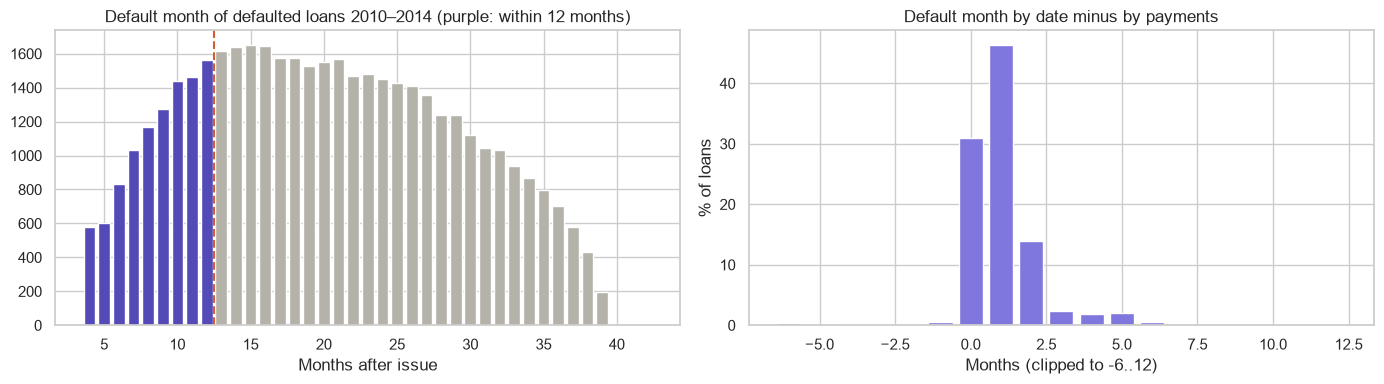

count    43095.0
mean        20.2
std          8.8
min          4.0
25%         13.0
50%         20.0
75%         27.0
max         90.0
Name: default_month, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
dm = mat["default_month"].clip(upper=42).value_counts().sort_index()
axes[0].bar(dm.index, dm.values, color=["#534AB7" if m <= HORIZON_MONTHS else "#B4B2A9" for m in dm.index])
axes[0].axvline(HORIZON_MONTHS + 0.5, color="#D85A30", ls="--")
axes[0].set_title("Default month of defaulted loans 2010–2014 (purple: within 12 months)")
axes[0].set_xlabel("Months after issue")
dd = d.clip(-6, 12).value_counts().sort_index()
axes[1].bar(dd.index, dd.values / len(d) * 100, color="#7F77DD")
axes[1].set_title("Default month by date minus by payments")
axes[1].set_xlabel("Months (clipped to -6..12)")
axes[1].set_ylabel("% of loans")
fig.tight_layout()
save(fig, "target_checks")
plt.show()
print(mat["default_month"].describe().round(1))

In [10]:
# Fully paid loans: the number of instalments must be plausible (<= 36, fewer when prepaid).
fp = base[base["issue_year"].between(2010, 2014) & base["loan_status"].isin(GOOD_STATUSES)]
mp = months_paid(fp)
print(mp.describe().round(2))
print(f"more than 37 instalments: {(mp > 37).mean():.3%}")

count    286624.00
mean         34.21
std           1.58
min          25.00
25%          34.00
50%          35.00
75%          35.00
max         119.00
dtype: float64


more than 37 instalments: 0.017%


In [11]:
# Off-schedule payment arrangements, by issue year.
flags = base.assign(hardship=base["hardship_flag"].eq("Y"),
                    settlement=base["debt_settlement_flag"].eq("Y"))
flags.groupby("issue_year")[["hardship", "settlement"]].agg(["sum", "mean"]).round(4)

hardship         settlement        
                sum    mean        sum    mean
issue_year                                    
2010              0  0.0000         22  0.0024
2011              0  0.0000         28  0.0020
2012              0  0.0000        228  0.0052
2013              0  0.0000        851  0.0085
2014              0  0.0000       2052  0.0126
2015              0  0.0000       6294  0.0222
2016             87  0.0003       7992  0.0247
2017            265  0.0008       3397  0.0106

## 4. Which columns may enter the model?

Every raw column is classified in [`src/features_config.py`](../src/features_config.py)
into exactly one group. The check below fails if a column is missing or duplicated.
On top of the groups, `TARGET_ONLY_COLS` lists the columns used to build the target;
`assert_no_leakage` will run on every feature matrix before training.

In [12]:
raw_cols = [c for c in loans.columns if c != "issue_year"]
check_coverage(raw_cols)
ct = column_table()
print("Target-only columns:", TARGET_ONLY_COLS)
ct["group"].value_counts().rename("columns").to_frame()

Target-only columns: ['last_pymnt_d', 'total_rec_prncp', 'total_rec_int', 'installment', 'recoveries']


,columns
group,
CANDIDATE,95
LEAKAGE,38
TECHNICAL,7
LENDER_SCORE,6
KEY,3
PROXY,2


In [13]:
ct[ct["group"] != "CANDIDATE"].sort_values(["group", "column"]).reset_index(drop=True)

,column,group,reason
0,issue_d,KEY,origination month: defines train / test / OOT
1,loan_status,KEY,source of the target
2,term,KEY,sample filter: 36-month loans only
3,collection_recovery_fee,LEAKAGE,post charge-off fee: implies default
4,debt_settlement_flag,LEAKAGE,debt settlement: implies default
5,debt_settlement_flag_date,LEAKAGE,debt settlement: implies default
6,deferral_term,LEAKAGE,"hardship programme, after origination"
7,hardship_amount,LEAKAGE,"hardship programme, after origination"
8,hardship_dpd,LEAKAGE,"hardship programme, after origination"
9,hardship_end_date,LEAKAGE,"hardship programme, after origination"


In [14]:
assert_no_leakage(GROUPS["CANDIDATE"])          # passes
try:
    assert_no_leakage(["fico_range_low", "dti", "installment", "recoveries"])
except AssertionError as e:
    print("Caught:", e)

Caught: forbidden columns in the feature matrix: ['installment', 'recoveries']


### 4.1 Why leakage matters: a demonstration

Columns known only after origination separate good and bad loans almost
perfectly, because they *describe* the outcome. A model using them would look
excellent in testing and be useless in production. Compare them with FICO,
the strongest legitimate predictor.

In [15]:
def gini(y, x):
    s = pd.Series(x).fillna(pd.Series(x).median())
    auc = roc_auc_score(y, s)
    return abs(2 * auc - 1)

demo = ["total_rec_prncp", "last_pymnt_amnt", "last_fico_range_high", "recoveries",
        "fico_range_low", "dti", "annual_inc"]
leak_demo = pd.DataFrame({
    "group": [ct.set_index("column").loc[c, "group"] for c in demo],
    "gini_12m": [gini(base[TARGET], base[c]) for c in demo],
}, index=demo).round(3)
leak_demo

,group,gini_12m
total_rec_prncp,LEAKAGE,0.904
last_pymnt_amnt,LEAKAGE,0.414
last_fico_range_high,LEAKAGE,0.770
recoveries,LEAKAGE,0.693
fico_range_low,CANDIDATE,0.176
dti,CANDIDATE,0.134
annual_inc,CANDIDATE,0.105


## 5. Candidate features: availability over time

Lending Club added bureau fields at different dates. A feature that is empty in
the training years cannot be learned, and a feature whose missingness changes
over time lets the model learn "missing = old loan".

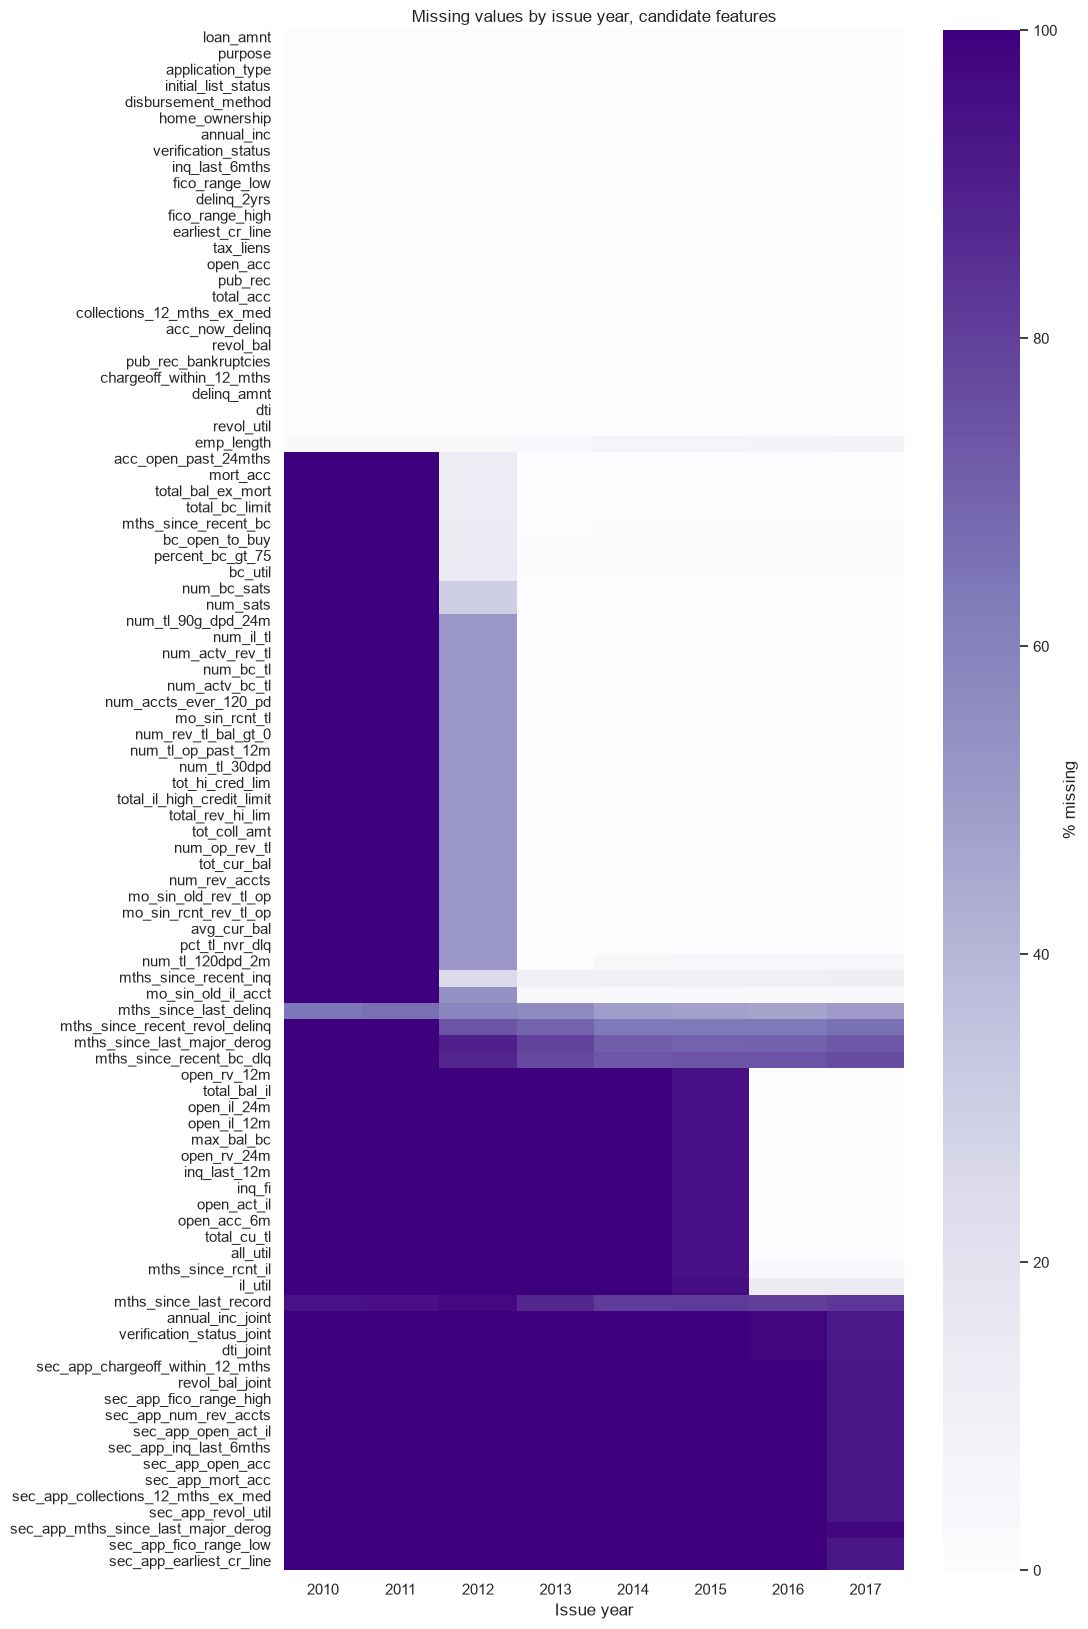

In [16]:
cand = list(GROUPS["CANDIDATE"])
miss_by_year = base.groupby("issue_year")[cand].apply(lambda d: d.isna().mean())
order = miss_by_year.loc[2010:2016].mean().sort_values().index
fig, ax = plt.subplots(figsize=(10, 20))
sns.heatmap(miss_by_year[order].T * 100, cmap="Purples", vmin=0, vmax=100,
            cbar_kws={"label": "% missing"}, ax=ax)
ax.set_title("Missing values by issue year, candidate features")
ax.set_xlabel("Issue year")
save(fig, "missing_by_year")
plt.show()

In [17]:
q = base.assign(q=base["issue_d"].dt.to_period("Q")).groupby("q")[cand].apply(lambda d: d.isna().mean())

def first_quarter_available(col, threshold=0.5):
    ok = q.index[q[col] < threshold]
    return str(ok.min()) if len(ok) else "never"

summary = pd.DataFrame({
    "missing_2010_11": miss_by_year.loc[2010:2011].mean(),
    "missing_2012_14": miss_by_year.loc[2012:2014].mean(),
    "missing_2015": miss_by_year.loc[2015],
    "missing_2016": miss_by_year.loc[2016],
    "missing_2017_oot": miss_by_year.loc[2017],
}).round(3)
summary["available_from"] = [first_quarter_available(c) for c in summary.index]
summary["available_from"].value_counts().sort_index()

available_from
2010Q1    26
2012Q2     9
2012Q3     2
2012Q4    24
2016Q1    14
never     20
Name: count, dtype: int64

In [18]:
summary[summary["available_from"] != "2010Q1"].sort_values("available_from")

,missing_2010_11,missing_2012_14,missing_2015,missing_2016,missing_2017_oot,available_from
acc_open_past_24mths,1.000,0.046,0.000,0.000,0.000,2012Q2
bc_open_to_buy,1.000,0.056,0.010,0.012,0.014,2012Q2
bc_util,1.000,0.056,0.011,0.012,0.014,2012Q2
mort_acc,1.000,0.046,0.000,0.000,0.000,2012Q2
mths_since_recent_bc,1.000,0.055,0.010,0.011,0.013,2012Q2
...,...,...,...,...,...,...
sec_app_mths_since_last_major_derog,1.000,1.000,1.000,1.000,0.975,never
mths_since_last_record,0.946,0.886,0.813,0.806,0.828,never
mths_since_last_major_derog,1.000,0.800,0.698,0.706,0.728,never
mths_since_recent_bc_dlq,1.000,0.794,0.738,0.742,0.765,never


### Joint applications

In [19]:
base.groupby("issue_year")["application_type"].value_counts().unstack(fill_value=0)

application_type,Individual,Joint App
issue_year,,
2010,9156,0
2011,14101,0
2012,43470,0
2013,100422,0
2014,162570,0
2015,282934,239
2016,318277,5218
2017,296484,23935


## 6. Default rate by Lending Club grade

Grade is the output of Lending Club's own model, so it is **not** a feature
(see `LENDER_SCORE`). It is useful as a sanity check and, later, as a benchmark
our model has to beat.

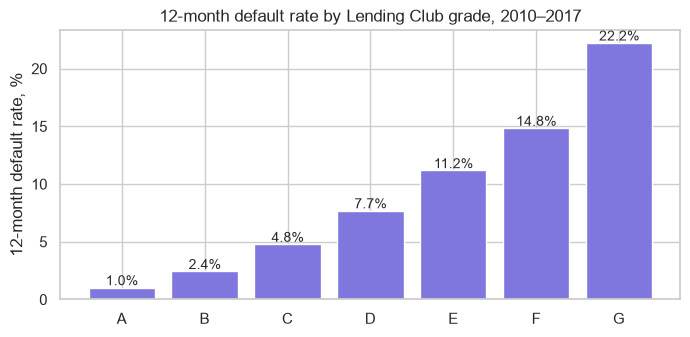

Gini of LC sub-grade, 12-month target, all years: 0.403
Gini of LC sub-grade, lifetime target, closed loans: 0.338


In [20]:
g = base.groupby("grade")[[TARGET, TARGET_LIFETIME]].mean() * 100
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(g.index, g[TARGET], color="#7F77DD")
for x, v in zip(g.index, g[TARGET]):
    ax.text(x, v + 0.2, f"{v:.1f}%", ha="center", fontsize=10)
ax.set_ylabel("12-month default rate, %")
ax.set_title("12-month default rate by Lending Club grade, 2010–2017")
save(fig, "dr_by_grade")
plt.show()

sg = base["sub_grade"].astype(str).rank(method="dense")
closed = base[TARGET_LIFETIME].notna()
print(f"Gini of LC sub-grade, 12-month target, all years: {gini(base[TARGET], sg):.3f}")
print(f"Gini of LC sub-grade, lifetime target, closed loans: "
      f"{gini(base.loc[closed, TARGET_LIFETIME], sg[closed]):.3f}")

In [21]:
# Gini of the benchmark by year: is the ranking stable over time?
pd.Series({y: gini(d[TARGET], d["sub_grade"].astype(str).rank(method="dense"))
           for y, d in base.groupby("issue_year")}, name="sub_grade_gini_12m").round(3).to_frame().T

,2010,2011,2012,2013,2014,2015,2016,2017
sub_grade_gini_12m,0.377,0.287,0.241,0.367,0.393,0.439,0.414,0.408


## 7. Key borrower characteristics

In [22]:
key = ["fico_range_low", "annual_inc", "dti", "loan_amnt", "revol_util", "inq_last_6mths"]
base[key].describe(percentiles=[0.01, 0.5, 0.99]).T.round(1)

,count,mean,std,min,1%,50%,99%,max
fico_range_low,1256806.0,696.2,32.2,660.0,660.0,690.0,800.0,845.0
annual_inc,1256806.0,74787.1,89791.5,0.0,16500.0,62000.0,265000.0,61000000.0
dti,1256452.0,18.1,11.0,-1.0,1.8,17.4,38.5,999.0
loan_amnt,1256806.0,12571.4,8316.8,1000.0,1500.0,10000.0,35000.0,40000.0
revol_util,1255924.0,51.0,24.4,0.0,1.4,50.9,98.2,892.3
inq_last_6mths,1256806.0,0.6,0.9,0.0,0.0,0.0,4.0,10.0


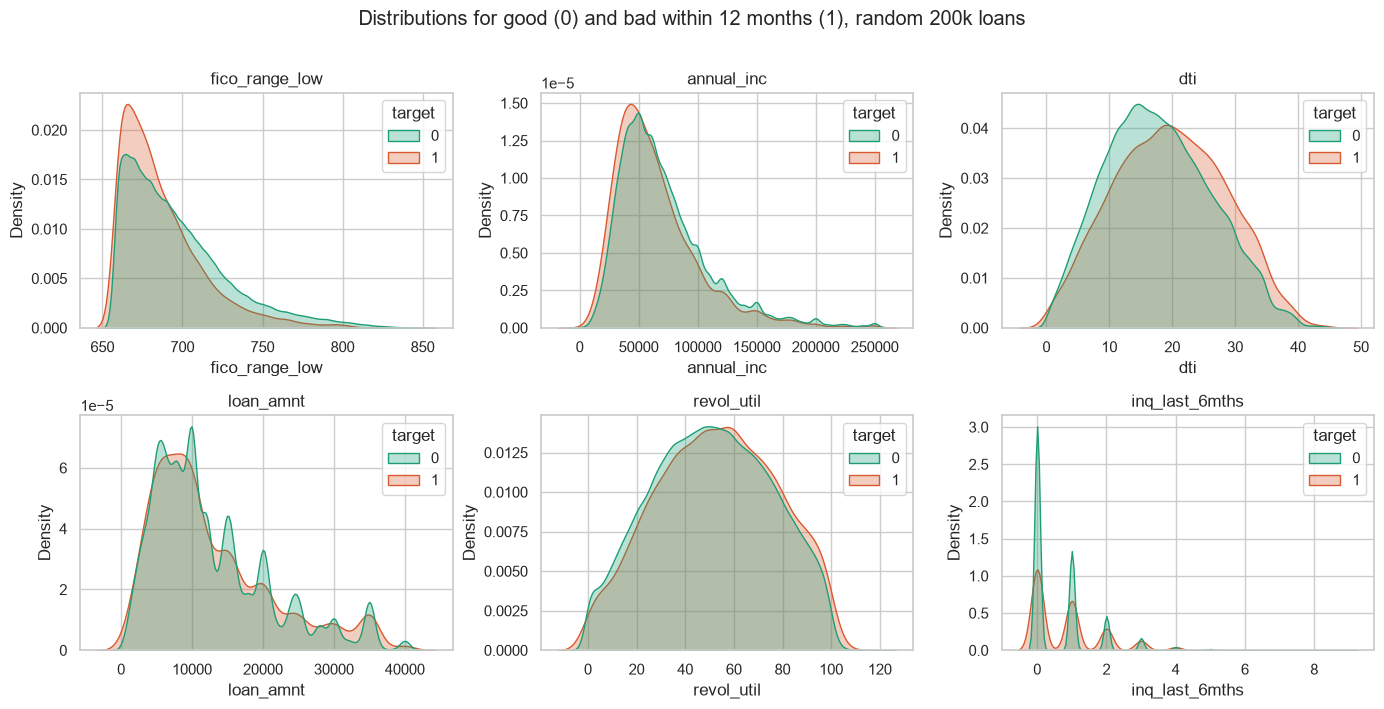

In [23]:
sample = base.sample(200_000, random_state=42)  # KDE on 1.2M rows is slow; shapes are the same
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
clip = {"annual_inc": 250_000, "dti": 45, "revol_util": 120}
for ax, c in zip(axes.flat, key):
    d = sample[[c, TARGET]].dropna().copy()
    if c in clip:
        d = d[d[c] <= clip[c]]
    sns.kdeplot(data=d, x=c, hue=TARGET, common_norm=False, fill=True, alpha=0.3,
                palette={0: "#1D9E75", 1: "#D85A30"}, ax=ax)
    ax.set_title(c)
fig.suptitle("Distributions for good (0) and bad within 12 months (1), random 200k loans", y=1.01)
fig.tight_layout()
save(fig, "distributions")
plt.show()

### Default rate by decile of each feature

A good predictor shows a clear, monotonic trend. Shape matters for WoE binning
and for monotone constraints in boosting later.

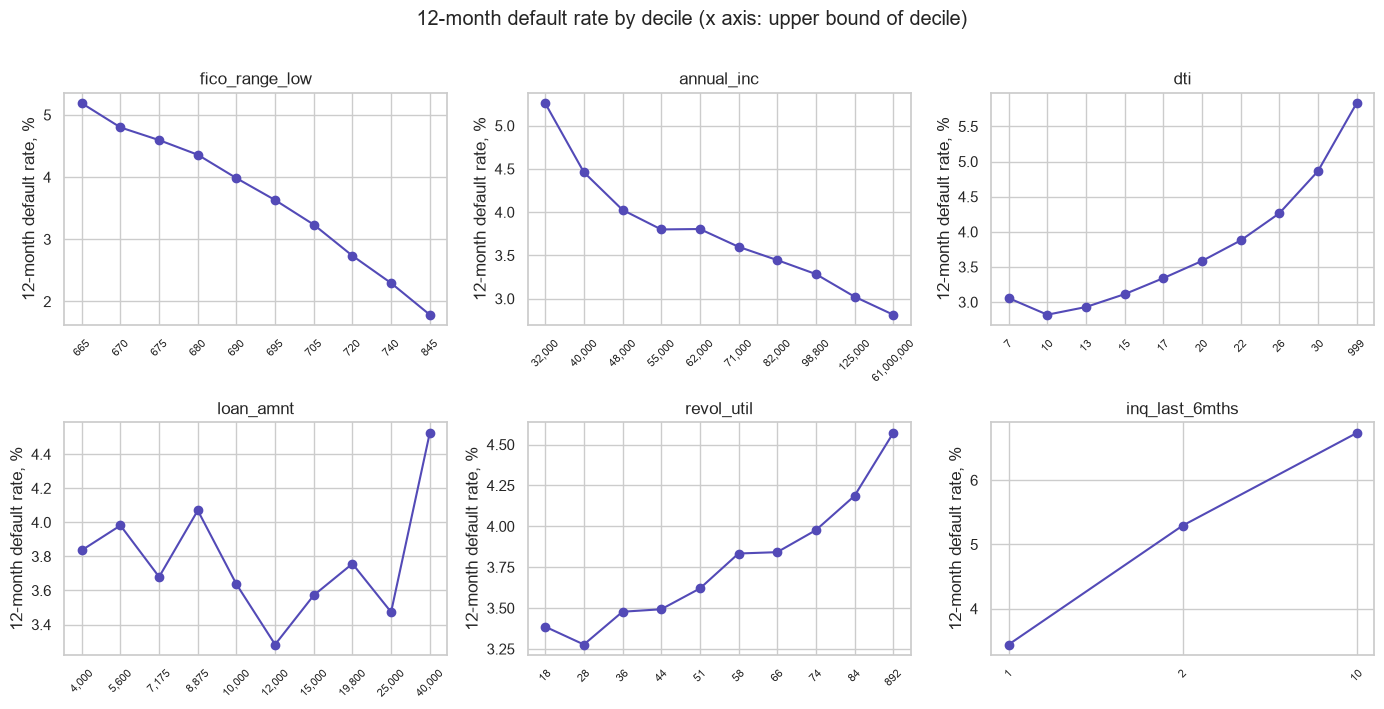

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, key):
    d = base[[c, TARGET]].dropna()
    q10 = pd.qcut(d[c], 10, duplicates="drop")
    r = d.groupby(q10, observed=True)[TARGET].mean() * 100
    ax.plot(range(len(r)), r.values, "o-", color="#534AB7")
    ax.set_xticks(range(len(r)))
    ax.set_xticklabels([f"{iv.right:,.0f}" for iv in r.index], rotation=45, fontsize=8)
    ax.set_title(c)
    ax.set_ylabel("12-month default rate, %")
fig.suptitle("12-month default rate by decile (x axis: upper bound of decile)", y=1.01)
fig.tight_layout()
save(fig, "dr_by_decile")
plt.show()

## 8. Anomalies

In [25]:
checks = {
    "annual_inc == 0": (base["annual_inc"] == 0),
    "annual_inc > 1M": (base["annual_inc"] > 1_000_000),
    "dti < 0": (base["dti"] < 0),
    "dti > 100": (base["dti"] > 100),
    "dti missing": base["dti"].isna(),
    "revol_util > 100": (base["revol_util"] > 100),
    "emp_length missing": base["emp_length"].isna(),
    "home_ownership in OTHER/NONE/ANY": base["home_ownership"].isin(["OTHER", "NONE", "ANY"]),
}
anom = pd.DataFrame({
    "loans": {k: int(v.sum()) for k, v in checks.items()},
    "default_rate_12m": {k: base.loc[v, TARGET].mean() if v.any() else np.nan for k, v in checks.items()},
})
anom["default_rate_12m"] = anom["default_rate_12m"].round(3)
anom

,loans,default_rate_12m
annual_inc == 0,338,0.041
annual_inc > 1M,282,0.025
dti < 0,1,0.000
dti > 100,538,0.046
dti missing,354,0.040
revol_util > 100,4362,0.059
emp_length missing,84983,0.056
home_ownership in OTHER/NONE/ANY,474,0.042


In [26]:
d = base[["emp_length", TARGET]].copy()
d["emp_length"] = d["emp_length"].fillna("missing")
d.groupby("emp_length")[TARGET].agg(loans="size", default_rate_12m="mean").round(3)

,loans,default_rate_12m
emp_length,,
1 year,84705,0.041
10+ years,397676,0.032
2 years,116604,0.038
3 years,102899,0.039
4 years,76566,0.038
5 years,78452,0.038
6 years,57632,0.037
7 years,52559,0.035
8 years,53128,0.035


## 9. Conclusions

### Sample and target
- **Target:** 90+ days past due within 12 months of issue (one-year PD, CRR Art. 178 default
  definition). The lifetime target is kept as `target_lifetime` for comparison only.
- **Data snapshot:** March 2019 (latest `last_pymnt_d`). With a 12-month window and a 3-month
  buffer, every loan issued up to December 2017 is usable; 2018 is not.
- **Modelling base:** 1,256,806 36-month loans issued 2010–2017, 12-month default rate **3.77%**,
  twice the size of a lifetime-target sample, which would have to stop at 2015.
- 12-month default rate by year: 2.9–3.7% in 2010–2015, **4.4% in 2016**, 4.1% in 2017.
  The 2016 rise matches Lending Club's looser credit policy at the time: a model trained on
  earlier years is expected to **under-predict** PD in the out-of-time year.
- Only about a quarter of lifetime defaults (21–33% in 2010–2015) happen within 12 months:
  the two targets answer different questions and their default rates are not comparable.

### Target reconstruction: checks on matured vintages 2010–2014
- The default month is reconstructed from the number of instalments paid, because the public
  data has no monthly payment history.
- Cross-check against the last payment date on 43,095 defaulted loans: the 12-month flag agrees
  in **96.3%** of loans; default months agree within 1 month for 78% and within 2 months for 92%.
- Disagreements go almost entirely one way (1,547 loans bad by payments but not by date, 36 the
  other way): the date is pushed later by post charge-off recoveries and debt settlements,
  as expected. The payment-count method is the primary one.
- The default-month distribution is smooth (minimum 4 = no payment at all, peak around month
  14–16), with no negative values. Fully paid loans have 25–36 instalments; above 37 only 0.017%.
- Hardship plans are negligible (≤ 0.08% of loans). Debt settlements reach 2.5% of loans in 2016
  and are the main source of method disagreement: kept in the sample (they are genuine defaults),
  listed as a limitation, with a sensitivity test in Part 2.

### Leakage control
- 151 raw columns are classified in `src/features_config.py`: 95 candidates, 38 leakage,
  6 lender-score, 2 geographic proxies, 7 technical, 3 keys. `TARGET_ONLY_COLS` lists the 5
  columns used to build the target; `assert_no_leakage` runs on every feature matrix.
- Leakage is not theoretical: `total_rec_prncp`, a target-building column, alone reaches Gini
  **0.90**, `last_fico_range_high` **0.77**, against **0.18** for application FICO, the strongest
  legitimate predictor.
- Lending Club sub-grade alone has Gini **0.40** on the 12-month target (0.24–0.44 by year). It is
  excluded from the model and kept as the **benchmark** our model has to beat.

### Feature availability: input for the training-window experiment (notebook 02)
- **35 bureau fields** (`mort_acc`, `bc_util`, `tot_cur_bal`, …) appear between **Q2 and Q4 2012**.
- **14 newer bureau fields** (`open_acc_6m`, `il_util`, `all_util`, `inq_last_12m`, …) appear in
  **Q1 2016**. With the out-of-time year 2017 they can now be learned, but only from 2016 data.
- This gives the experiment its candidates. Out-of-time is 2017; the window is chosen on a
  separate validation slice (H2 2016), never on the out-of-time year. Windows to compare:
  H1 2016, 2015–H1 2016 and 2013–H1 2016, each with and without the 2016 fields.
- `mths_since_*` fields are missing when the event never happened: missing is
  **informative**, not a data gap, and must be binned separately, not imputed.

### Data quality
- **Joint applications** appear in late 2015 and reach 7.5% of 2017 loans (23,935). Their 16
  joint/co-borrower fields exist only for them. Decision: **scope = individual applications**;
  joint applications are excluded and listed as a limitation.
- `emp_length` missing for 6.8% of loans, with a higher default rate (5.6% vs 3.8%):
  keep "missing" as its own category.
- Isolated anomalies (`dti` = 999, `annual_inc` = 0 or > 1M, `revol_util` > 100) affect
  a few thousand loans at most: handled by capping in binning, not by deletion.

### Limitations, carried into Part 2 (validation)
- The target is a **reconstruction**, not observed 90+ dpd: delinquencies that were later cured
  are invisible, and partial prepayments before default push the default month later. Both make
  the 12-month default rate slightly too low.
- Debt settlements make the payment schedule irregular (sensitivity test planned).
- Default-rate drift 2015 → 2016 and its effect on calibration.
- The 2010–2017 window has no recession: PD is not a through-the-cycle estimate.
- Only funded loans are observed (no reject inference).